# 02. Dataset Inventory & Schema Analysis

## 2.1 Data Understanding

Tahap ini bertujuan untuk memahami struktur dan karakteristik dataset yang digunakan dalam kompetisi Datavidia 11.0 Task 1.

Dataset terdiri dari sembilan tabel yang mencakup informasi pengiriman, pelanggan, kurir, pusat distribusi, aktivitas operasional, rute perjalanan, dan transaksi pembayaran.

Analisis dilakukan terhadap data training dan testing untuk mengidentifikasi:

1. Ukuran dan struktur setiap tabel.
2. Nama kolom dan tipe data.
3. Missing values pada setiap fitur.
4. Jumlah nilai unik dan cardinality.
5. Konsistensi skema antara training dan testing.
6. Karakteristik awal identifier dan categorical features.

Hasil analisis ini akan digunakan sebagai dasar untuk menentukan strategi preprocessing, data integration, dan feature engineering.

## 2.2 Dataset Inventory

Dataset dikelompokkan menjadi tiga kategori utama:

- Main Transaction: shipments.
- Operational Transaction: scan_events, route_segments, dan invoices.
- Master Data: customers, couriers, hubs, service_packages, dan promotions.

Setiap tabel akan dianalisis secara terpisah sebelum dilakukan proses penggabungan data.

In [27]:
import os
from pathlib import Path

import polars as pl
import pandas as pd
import numpy as np

DATA_DIR = Path(r"c:\Users\ASUS\.vscode\arkavidia\data\Task-1-Datavidia-11.0")

TABLES = {
    "shipments": "Main Transaction",
    "scan_events": "Operational Transaction",
    "route_segments": "Operational Transaction",
    "invoices": "Operational Transaction",
    "customers": "Master Data",
    "couriers": "Master Data",
    "hubs": "Master Data",
    "service_packages": "Master Data",
    "promotions": "Master Data"
}

SPLITS = ["train", "test"]

for split in SPLITS:
    for table in TABLES:
        path = DATA_DIR / split / f"{table}.csv"
        if not path.exists():
            raise FileNotFoundError(path)

print("Dataset directory:", DATA_DIR.resolve())
print("Total tables:", len(TABLES))
print("Available splits:", SPLITS)

Dataset directory: C:\Users\ASUS\.vscode\arkavidia\data\Task-1-Datavidia-11.0
Total tables: 9
Available splits: ['train', 'test']


In [28]:
inventory_records = []

for split in SPLITS:
    for table, category in TABLES.items():

        path = DATA_DIR / split / f"{table}.csv"

        lf = pl.scan_csv(
            path,
            infer_schema_length=20000
        )

        schema = lf.collect_schema()

        n_rows = lf.select(
            pl.len()
        ).collect().item()

        inventory_records.append({
            "Split": split,
            "Table": table,
            "Category": category,
            "Rows": n_rows,
            "Columns": len(schema),
            "Memory Format": "CSV"
        })

inventory_df = pd.DataFrame(inventory_records)

display(
    inventory_df.sort_values(
        ["Split", "Category", "Table"]
    ).reset_index(drop=True)
)

,Split,Table,Category,Rows,Columns,Memory Format
0,test,shipments,Main Transaction,362245,37,CSV
1,test,couriers,Master Data,23806,11,CSV
2,test,customers,Master Data,573841,14,CSV
3,test,hubs,Master Data,654,9,CSV
4,test,promotions,Master Data,34,6,CSV
5,test,service_packages,Master Data,62,10,CSV
6,test,invoices,Operational Transaction,427458,12,CSV
7,test,route_segments,Operational Transaction,641446,8,CSV
8,test,scan_events,Operational Transaction,1993132,8,CSV
9,train,shipments,Main Transaction,1243617,38,CSV


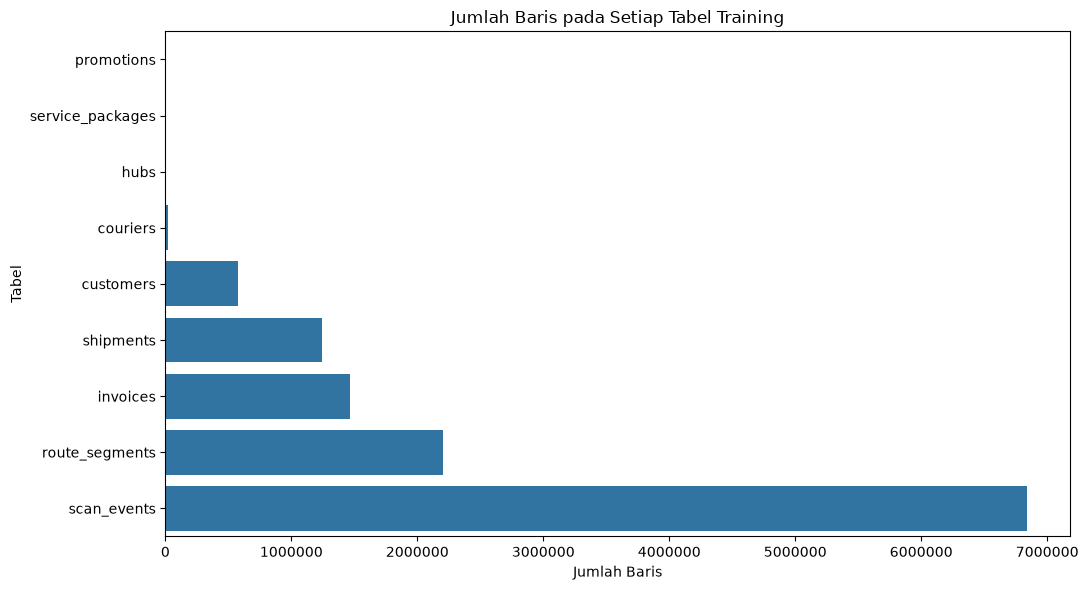

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

train_inventory = inventory_df[
    inventory_df["Split"] == "train"
].sort_values("Rows", ascending=True)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=train_inventory,
    x="Rows",
    y="Table"
)

plt.title("Jumlah Baris pada Setiap Tabel Training")
plt.xlabel("Jumlah Baris")
plt.ylabel("Tabel")
plt.ticklabel_format(
    style="plain",
    axis="x"
)

plt.tight_layout()
plt.show()

notes: 
1. tabel data terbesar di scan events
2. tabel operasional punya data yg lebih besar dari data utama 
3. dari ukuran data bisa dilihat ada relasi one to many

## 2.3 Schema Analysis

Schema analysis dilakukan untuk memahami karakteristik setiap kolom dalam dataset.

Informasi yang dianalisis mencakup:

- Nama kolom.
- Tipe data.
- Tabel asal.
- Dataset split.
- Jumlah nilai kosong.
- Jumlah nilai unik.

Analisis tipe data diperlukan untuk menentukan pendekatan preprocessing yang tepat.

Secara umum, fitur akan dikelompokkan menjadi:
1. Numerical Features: fitur numerik yang dapat digunakan dalam operasi matematis.
2. Categorical Features: fitur kategorikal yang merepresentasikan kelompok atau kategori.
3. Identifier Features: fitur identitas seperti shipment_id, customer_id, dan courier_id.
4. Target Features: variabel status_penanganan yang menjadi label klasifikasi.

Identifikasi jenis fitur dilakukan berdasarkan tipe data dan karakteristik aktual setiap kolom.

In [30]:
schema_records = []
profile_records = []

for split in SPLITS:
    for table, category in TABLES.items():

        path = DATA_DIR / split / f"{table}.csv"

        lf = pl.scan_csv(
            path,
            infer_schema_length=20000
        )

        schema = lf.collect_schema()
        columns = list(schema.keys())

        expressions = [
            pl.len().alias("n_rows")
        ]

        for i, column in enumerate(columns):

            expressions.append(
                pl.col(column).null_count().alias(f"null_{i}")
            )

            expressions.append(
                pl.col(column).approx_n_unique().alias(f"unique_{i}")
            )

            if schema[column] == pl.String:
                expressions.append(
                    pl.col(column)
                    .str.strip_chars()
                    .eq("")
                    .sum()
                    .alias(f"blank_{i}")
                )
            else:
                expressions.append(
                    pl.lit(0).alias(f"blank_{i}")
                )

        stats = lf.select(expressions).collect()

        n_rows = stats["n_rows"][0]

        for i, column in enumerate(columns):

            dtype = str(schema[column])

            null_count = stats[f"null_{i}"][0]
            blank_count = stats[f"blank_{i}"][0]
            unique_count = stats[f"unique_{i}"][0]

            missing_count = null_count + blank_count

            unique_ratio = (
                unique_count / n_rows
                if n_rows > 0 else 0
            )

            schema_records.append({
                "Split": split,
                "Table": table,
                "Column": column,
                "Data Type": dtype
            })

            profile_records.append({
                "Split": split,
                "Table": table,
                "Category": category,
                "Column": column,
                "Data Type": dtype,
                "Null Count": null_count,
                "Blank Count": blank_count,
                "Missing Count": missing_count,
                "Missing Percentage": (
                    missing_count / n_rows * 100
                    if n_rows > 0 else 0
                ),
                "Approx Unique": unique_count,
                "Unique Ratio": unique_ratio
            })

schema_df = pd.DataFrame(schema_records)
profile_df = pd.DataFrame(profile_records)

print("Schema analysis completed.")
print("Total schema records:", len(schema_df))
print("Total column profiles:", len(profile_df))

Schema analysis completed.
Total schema records: 231
Total column profiles: 231


In [31]:
display(
    schema_df[
        schema_df["Split"] == "train"
    ].sort_values(
        ["Table", "Column"]
    ).reset_index(drop=True)
)

,Split,Table,Column,Data Type
0,train,couriers,contract_type,String
1,train,couriers,courier_id,String
2,train,couriers,courier_score,Float64
3,train,couriers,experience_years,Int64
4,train,couriers,hub_id,String
...,...,...,...,...
111,train,shipments,skor_prioritas_kirim,Float64
112,train,shipments,status_penanganan,String
113,train,shipments,varian_cuaca_rute,Float64
114,train,shipments,volume_l,Float64


In [32]:
missing_df = profile_df[
    profile_df["Missing Count"] > 0
].copy()

missing_df = missing_df.sort_values(
    "Missing Percentage",
    ascending=False
)

display(
    missing_df[
        [
            "Split",
            "Table",
            "Column",
            "Null Count",
            "Blank Count",
            "Missing Percentage"
        ]
    ].reset_index(drop=True)
)

,Split,Table,Column,Null Count,Blank Count,Missing Percentage
0,train,invoices,discount,622355,0,42.402785
1,test,invoices,discount,181088,0,42.363928
2,test,shipments,volume_l,11013,0,3.040208
3,train,shipments,volume_l,37012,0,2.976157
4,test,route_segments,durasi_jam,12824,0,1.999233
5,train,route_segments,durasi_jam,43968,0,1.998411
6,test,customers,credit_score,11429,0,1.991667
7,train,customers,credit_score,11429,0,1.991667
8,train,couriers,courier_score,256,0,1.075359
9,test,couriers,courier_score,256,0,1.075359


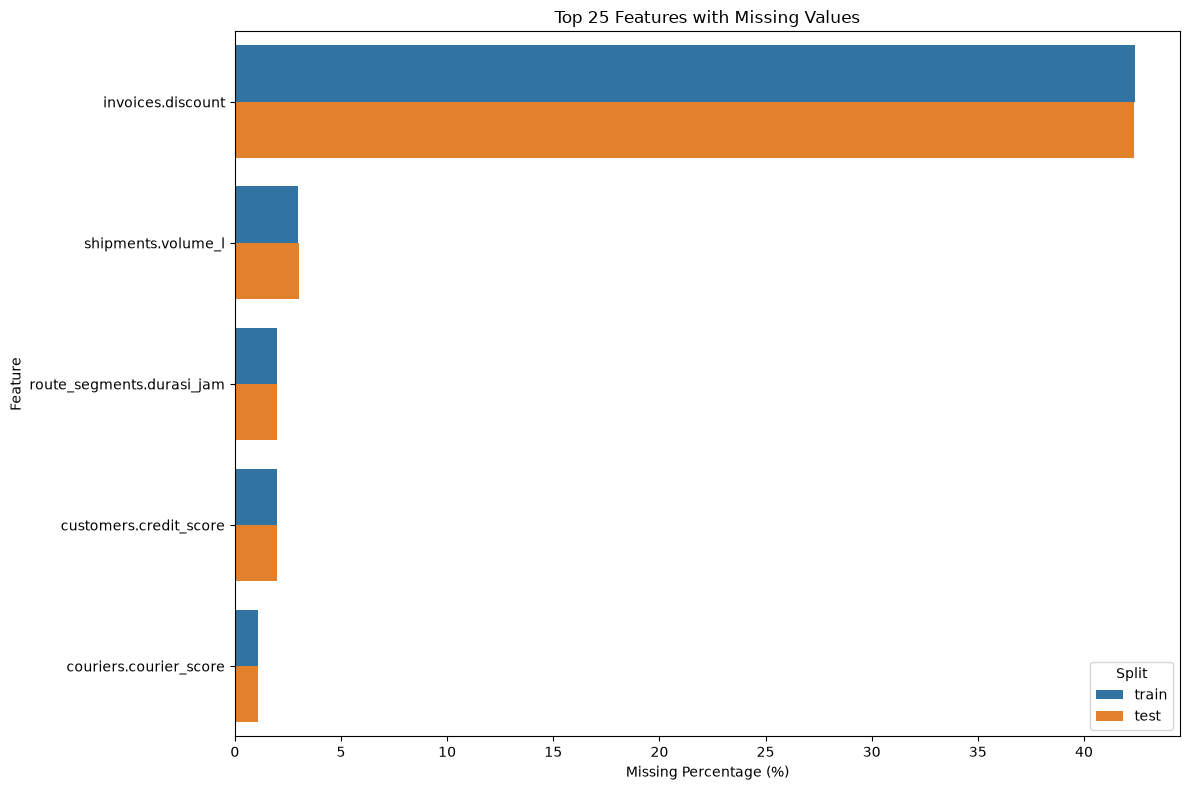

In [33]:
missing_plot = profile_df[
    profile_df["Missing Count"] > 0
].copy()

missing_plot["Feature"] = (
    missing_plot["Table"] + "." +
    missing_plot["Column"]
)

missing_plot = missing_plot.sort_values(
    "Missing Percentage",
    ascending=False
).head(25)

if not missing_plot.empty:

    plt.figure(figsize=(12, 8))

    sns.barplot(
        data=missing_plot,
        x="Missing Percentage",
        y="Feature",
        hue="Split"
    )

    plt.title("Top 25 Features with Missing Values")
    plt.xlabel("Missing Percentage (%)")
    plt.ylabel("Feature")

    plt.tight_layout()
    plt.show()

else:
    print("Tidak ditemukan missing values.")

notes:
1. yang memiliki missing values tertinggi itu invoice di column discount 
2. perbedaan missing values antara train dan test cukup kecil sekitar 0,1 sekian
3. missing values hanya muncuk pada data invoice kolom discount, shipments kolom volume_i, route_segments kolom durasi_jam, customers kolom credit_score, dan couriers kolom couriers_score

In [34]:
def categorize_cardinality(row):

    column = row["Column"].lower()
    dtype = row["Data Type"]
    unique = row["Approx Unique"]

    if column == "shipment_id" or column.endswith("_id"):
        return "Identifier Candidate"

    if dtype == "String":

        if unique <= 20:
            return "Low Cardinality"

        elif unique <= 500:
            return "Medium Cardinality"

        return "High Cardinality"

    if unique <= 20:
        return "Low Cardinality"

    return "Numerical / High Uniqueness"


profile_df["Cardinality Group"] = profile_df.apply(
    categorize_cardinality,
    axis=1
)

cardinality_df = profile_df[
    profile_df["Split"] == "train"
][
    [
        "Table",
        "Column",
        "Data Type",
        "Approx Unique",
        "Unique Ratio",
        "Cardinality Group"
    ]
].sort_values(
    "Approx Unique",
    ascending=False
)

display(cardinality_df.reset_index(drop=True))

,Table,Column,Data Type,Approx Unique,Unique Ratio,Cardinality Group
0,scan_events,event_id,String,6227701,0.910867,Identifier Candidate
1,route_segments,segment_id,String,2224001,1.010842,Identifier Candidate
2,invoices,invoice_id,String,1316390,0.896893,Identifier Candidate
3,shipments,shipment_id,String,1185380,0.953171,Identifier Candidate
4,route_segments,shipment_id,String,1185380,0.538773,Identifier Candidate
...,...,...,...,...,...,...
111,invoices,is_penalty,Int64,2,0.000001,Low Cardinality
112,customers,is_verified,Int64,2,0.000003,Low Cardinality
113,couriers,sertifikasi_hazardous,Int64,2,0.000084,Low Cardinality
114,service_packages,cod_allowed,Int64,2,0.032258,Low Cardinality


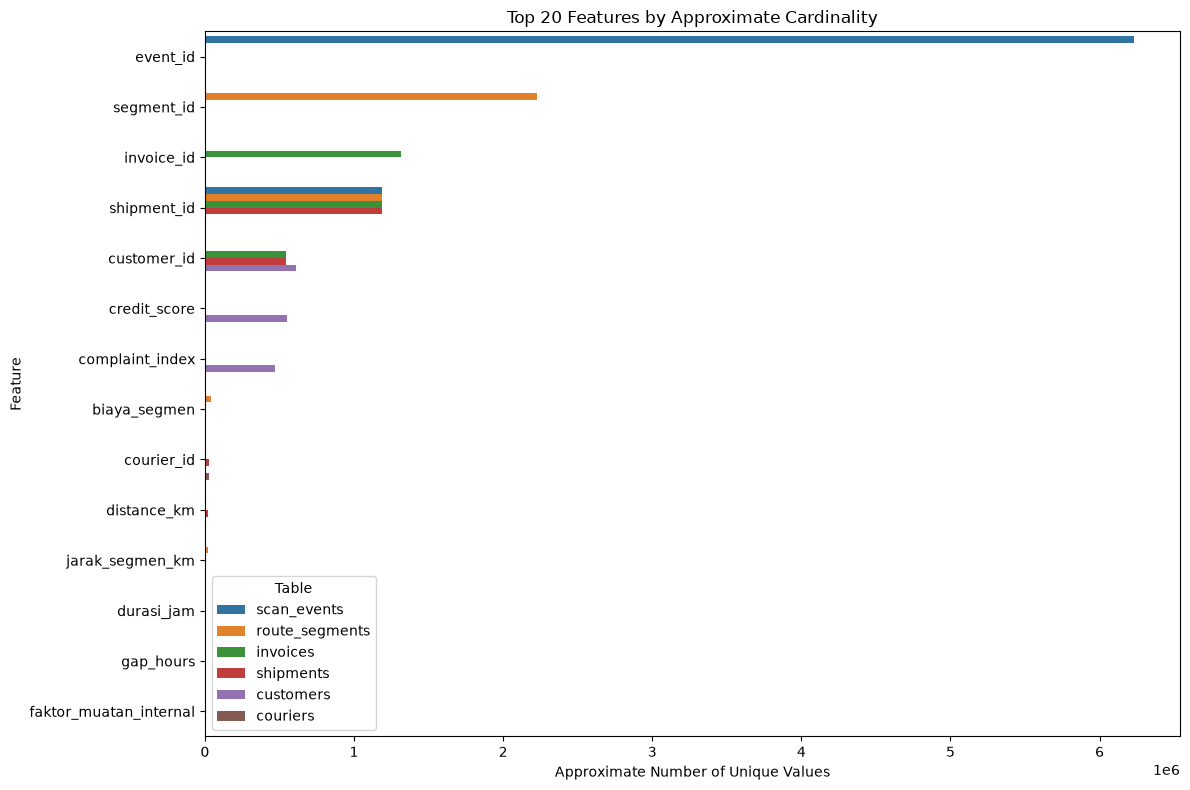

In [35]:
top_cardinality = cardinality_df.sort_values(
    "Approx Unique",
    ascending=False
).head(20)

plt.figure(figsize=(12, 8))

sns.barplot(
    data=top_cardinality,
    x="Approx Unique",
    y="Column",
    hue="Table"
)

plt.title("Top 20 Features by Approximate Cardinality")
plt.xlabel("Approximate Number of Unique Values")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()


notes:
1. identifier yang memiliki cardinality tertinggi adalah events_id
2. kategorikal fitur dengan ratusan kategori? keknya ngga ada
3. terdapat fitur numerik event id yang memiliki banyak nilai unik di scant_events 
4. blm ada ide apakah identifier tertentu bisa di manfaatkan freq encodingnya



In [36]:
schema_comparison = []

for table in TABLES:

    train_schema = schema_df[
        (schema_df["Split"] == "train") &
        (schema_df["Table"] == table)
    ]

    test_schema = schema_df[
        (schema_df["Split"] == "test") &
        (schema_df["Table"] == table)
    ]

    train_columns = set(train_schema["Column"])
    test_columns = set(test_schema["Column"])

    train_types = dict(
        zip(train_schema["Column"], train_schema["Data Type"])
    )

    test_types = dict(
        zip(test_schema["Column"], test_schema["Data Type"])
    )

    missing_in_test = sorted(
        train_columns - test_columns
    )

    extra_in_test = sorted(
        test_columns - train_columns
    )

    common_columns = train_columns & test_columns

    dtype_mismatch = [
        column
        for column in common_columns
        if train_types[column] != test_types[column]
    ]

    schema_comparison.append({
        "Table": table,
        "Train Columns": len(train_columns),
        "Test Columns": len(test_columns),
        "Missing in Test": missing_in_test,
        "Extra in Test": extra_in_test,
        "Dtype Mismatch": dtype_mismatch,
        "Schema Consistent": (
            not missing_in_test
            and not extra_in_test
            and not dtype_mismatch
        )
    })

schema_comparison_df = pd.DataFrame(schema_comparison)

display(schema_comparison_df)

,Table,Train Columns,Test Columns,Missing in Test,Extra in Test,Dtype Mismatch,Schema Consistent
0,shipments,38,37,[status_penanganan],[],[],False
1,scan_events,8,8,[],[],[],True
2,route_segments,8,8,[],[],[],True
3,invoices,12,12,[],[],[],True
4,customers,14,14,[],[],[],True
5,couriers,11,11,[],[],[],True
6,hubs,9,9,[],[],[],True
7,service_packages,10,10,[],[],[],True
8,promotions,6,6,[],[],[],True


## 2.4 Preliminary Findings

Berdasarkan hasil pemeriksaan dataset, dilakukan identifikasi awal terhadap karakteristik data.

Beberapa aspek yang menjadi perhatian utama:

1. Dataset terdiri dari sembilan tabel dengan karakteristik dan volume data berbeda.
2. Tabel operasional memiliki potensi relasi one-to-many terhadap shipment.
3. Fitur identifier dan categorical memiliki tingkat cardinality yang beragam.
4. Missing values perlu dianalisis berdasarkan distribusi dan makna bisnisnya.
5. Struktur dan tipe data train dan test harus dipastikan konsisten.
6. Fitur dengan cardinality tinggi memerlukan strategi encoding yang sesuai.

Hasil dari tahap ini akan menjadi dasar untuk menentukan preprocessing dan strategi integrasi data pada tahap berikutnya.

Kesimpulan akhir akan ditentukan setelah seluruh hasil inventory dan schema analysis diperiksa.

In [37]:
OUTPUT_DIR = Path("eda_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

inventory_df.to_csv(
    OUTPUT_DIR / "dataset_inventory.csv",
    index=False
)

schema_df.to_csv(
    OUTPUT_DIR / "dataset_schema.csv",
    index=False
)

profile_df.to_csv(
    OUTPUT_DIR / "column_profile.csv",
    index=False
)

missing_df.to_csv(
    OUTPUT_DIR / "missing_values.csv",
    index=False
)

cardinality_df.to_csv(
    OUTPUT_DIR / "cardinality_analysis.csv",
    index=False
)

schema_comparison_df.to_csv(
    OUTPUT_DIR / "schema_comparison.csv",
    index=False
)

print("Seluruh hasil analisis berhasil disimpan.")
print("Output directory:", OUTPUT_DIR.resolve())

Seluruh hasil analisis berhasil disimpan.
Output directory: C:\Users\ASUS\.vscode\arkavidia\eda_outputs
